# Step 6: The workflow diagram, drawn from the real LangGraph

Run all cells (Run All). The diagram appears below, nothing to copy or paste, and no API key is needed.

The graph is built from the same `agent/graph.py` the app uses. A dummy model is passed in, so no model is called and nothing leaves your computer.
Read-only: this notebook changes no data file.

**How to read the picture.** Teal boxes call the model (`read_email`, `explain`). Navy boxes are plain Python. Dashed arrows are conditional routes, solid arrows are fixed. The three dashed arrows that go round the outside are the early exits to `route`: an email that cannot be read, or has no batch, an unknown batch or no sender, and a claim that is not in the file. All of them end as "needs a person".

In [4]:
# 1. Find the pilot folder and build the graph (no key, no network)
import sys
from pathlib import Path
here = Path.cwd()
pilot = next(p for p in (here / 'pilot', here.parent / 'pilot', here) if (p / 'agent' / 'graph.py').exists())
sys.path.insert(0, str(pilot))
from agent.graph import build
graph = build(model_call=lambda system, user: '')        # dummy model: nothing is called
g = graph.get_graph()
nodes = list(g.nodes)
edges = [(e.source, e.target, bool(e.conditional)) for e in g.edges]
print(len(nodes), 'nodes,', len(edges), 'edges')
print('nodes:', ', '.join(nodes))

13 nodes, 21 edges
nodes: __start__, read_email, fetch, check_R1, check_R2, check_R3, check_R4, check_R5, check_R6, check_R12, route, explain, __end__


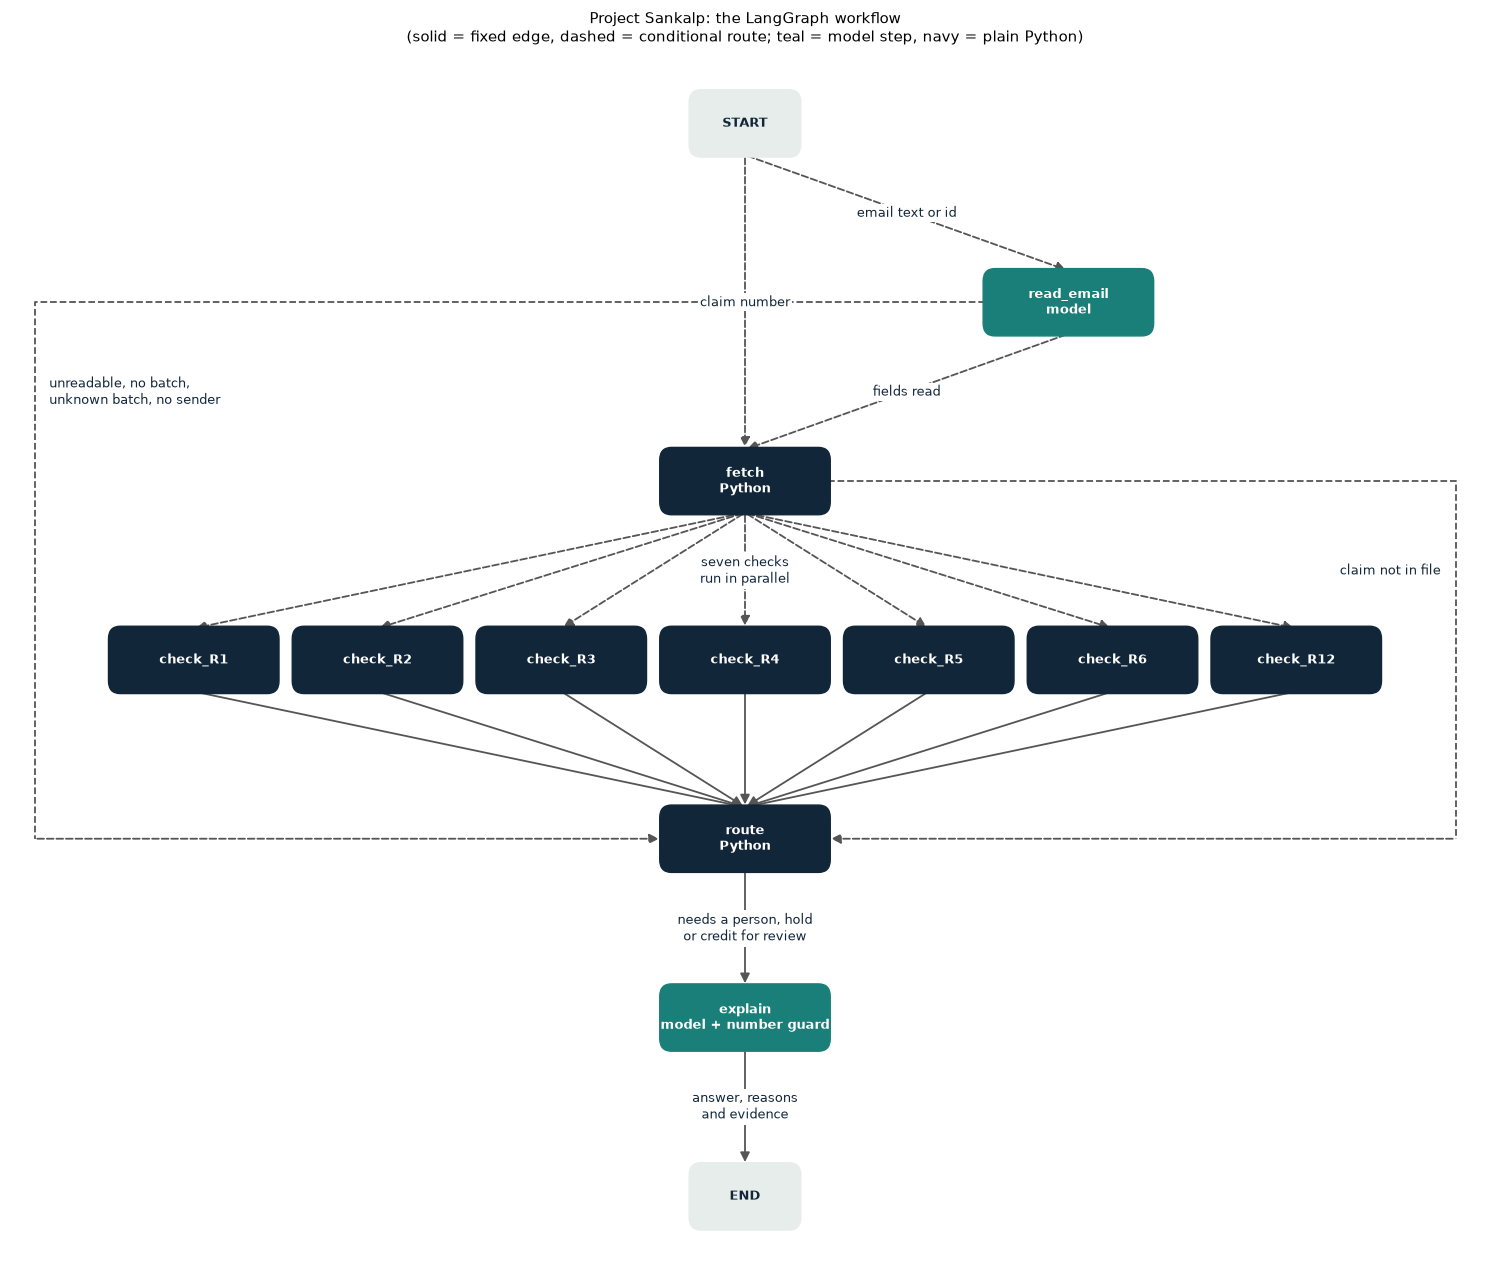

Saved d:\FDE\Assignments\langgraph\pfizer-channel-engagement_learner-pack\pilot\docs\workflow.png


In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

MODEL = {"read_email", "explain"}
LABEL = {"__start__": "START", "__end__": "END", "read_email": "read_email\nmodel", "fetch": "fetch\nPython",
         "route": "route\nPython", "explain": "explain\nmodel + number guard"}


def draw_graph(nodes, edges, labels=None, title="Project Sankalp: the LangGraph workflow"):
    """nodes: list of ids. edges: list of (source, target, conditional). labels: {(source, target): text} shown on the edge. Offline, no network.
    Rows = longest path from START. An edge that jumps over a row goes round the outside so it never hides behind a box."""
    depth = {n: 0 for n in nodes}
    for _ in nodes:
        for s, t, _c in edges:
            depth[t] = max(depth[t], depth[s] + 1)
    layers = {}
    for n in nodes:
        layers.setdefault(depth[n], []).append(n)
    spanned = {d for s, t, _c in edges if depth[t] - depth[s] == 2 for d in range(depth[s] + 1, depth[t])}   # rows that a two-row jump passes over
    W, H = 15.0, 1.7
    pos = {}
    for d, ns in layers.items():
        ns = sorted(ns, key=nodes.index)
        if len(ns) == 1 and d in spanned and d > 0:
            pos[ns[0]] = (W * 0.72, -d * H)                  # step aside so the edge that jumps over this row stays visible
            continue
        for i, n in enumerate(ns):
            pos[n] = ((i + 1) * W / (len(ns) + 1), -d * H)
    fig, ax = plt.subplots(figsize=(15, H * len(layers) + 1.0))
    side, labels = {}, (labels or {})
    for s, t, cond in edges:
        (x1, y1), (x2, y2) = pos[s], pos[t]
        ls = "--" if cond else "-"
        blocked = any(depth[s] < depth[n] < depth[t] and abs(pos[n][0] - (x1 + x2) / 2) < 1.0 for n in pos)
        if depth[t] - depth[s] > 2 or (depth[t] - depth[s] == 2 and blocked):
            k = side.get(t, 0); side[t] = k + 1            # alternate right and left margins
            mx = W - 0.25 if k % 2 == 0 else 0.25
            ax.plot([x1 + (0.85 if mx > x1 else -0.85), mx, mx], [y1, y1, y2], color="#555", lw=1.3, ls=ls, zorder=1)
            ax.add_patch(FancyArrowPatch((mx, y2), (x2 + (0.85 if mx > x2 else -0.85), y2), arrowstyle="-|>", mutation_scale=14, lw=1.3,
                                         color="#555", linestyle=ls, zorder=1))
            if (s, t) in labels:                      # beside the vertical run, on the inside of the margin line
                ax.text(mx + (-0.15 if mx > x1 else 0.15), y1 - 0.85, labels[(s, t)], ha="right" if mx > x1 else "left", va="center",
                        fontsize=9, color="#12263A", bbox=dict(fc="white", ec="none", pad=1.5), zorder=4)
        else:
            ax.add_patch(FancyArrowPatch((x1, y1 - 0.3), (x2, y2 + 0.3), arrowstyle="-|>", mutation_scale=14, lw=1.3, color="#555", linestyle=ls, zorder=1))
            if (s, t) in labels:
                ax.text((x1 + x2) / 2, (y1 + y2) / 2, labels[(s, t)], ha="center", va="center", fontsize=9, color="#12263A",
                        bbox=dict(fc="white", ec="none", pad=1.5), zorder=4)
    for n, (x, y) in pos.items():
        colour = "#1B7F79" if n in MODEL else ("#E7EDEB" if n.startswith("__") else "#12263A")
        text = "#12263A" if n.startswith("__") else "white"
        w = 1.1 if n.startswith("__") else 1.7
        ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.3), w, 0.6, boxstyle="round,pad=0.02,rounding_size=0.12", fc=colour, ec=colour, zorder=2))
        ax.text(x, y, LABEL.get(n, n), ha="center", va="center", color=text, fontsize=9, fontweight="bold", zorder=3)
    ax.set_xlim(0, W); ax.set_ylim(-H * (len(layers) - 1) - 0.7, 0.7); ax.axis("off")
    ax.set_title(title + "\n(solid = fixed edge, dashed = conditional route; teal = model step, navy = plain Python)", fontsize=11)
    plt.tight_layout()
    return fig


# Text on the arrows. LangGraph does not store names for conditional routes, so they are written here, one line per arrow.
EDGE_LABELS = {
    ('__start__', 'fetch'): 'claim number',
    ('__start__', 'read_email'): 'email text or id',
    ('read_email', 'fetch'): 'fields read',
    ('read_email', 'route'): 'unreadable, no batch,\nunknown batch, no sender',
    ('fetch', 'route'): 'claim not in file',
    ('fetch', 'check_R4'): 'seven checks\nrun in parallel',
    ('route', 'explain'): 'needs a person, hold\nor credit for review',
    ('explain', '__end__'): 'answer, reasons\nand evidence',
}

# 2. Draw it
fig = draw_graph(nodes, edges, EDGE_LABELS)
out = pilot / 'docs'; out.mkdir(exist_ok=True)
fig.savefig(out / 'workflow.png', dpi=150, bbox_inches='tight')     # saved for the README and the deck
plt.show()
print('Saved', out / 'workflow.png')

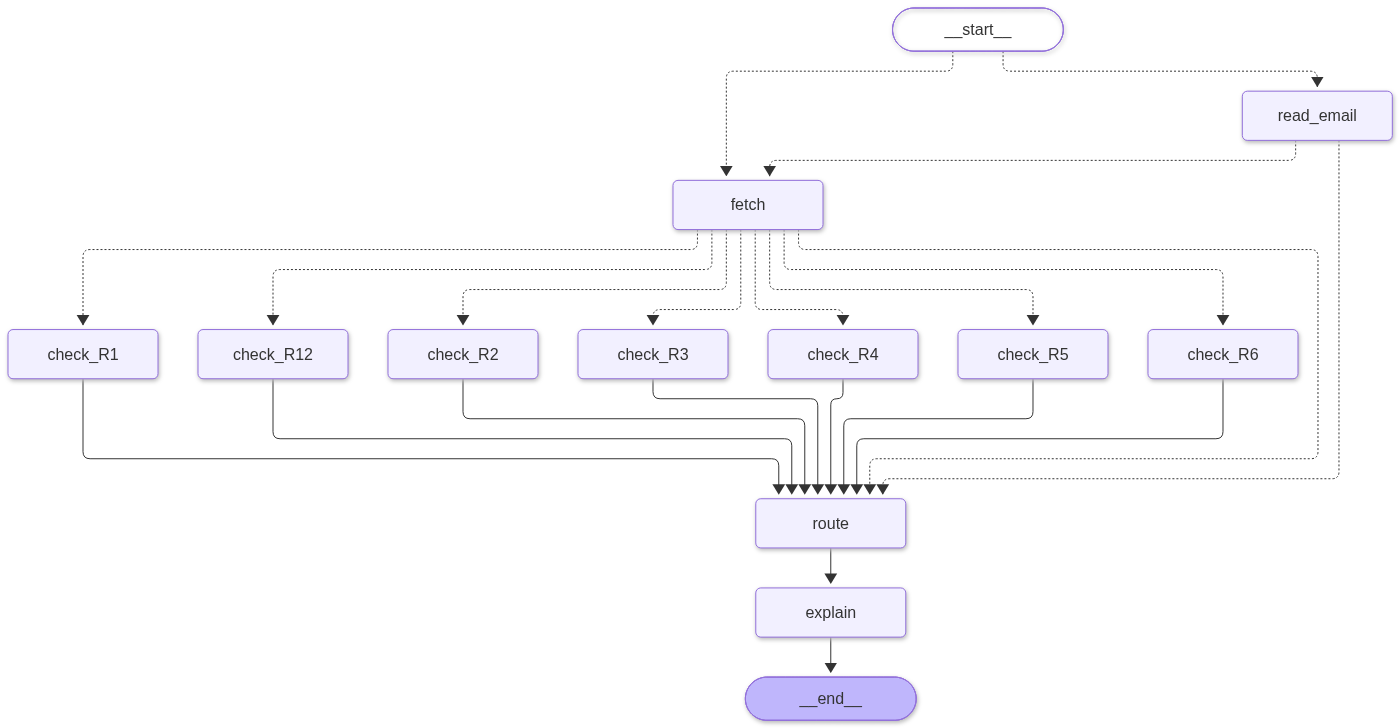

In [6]:
# 3. Optional: LangGraph's own picture. It is drawn by an outside website (mermaid.ink), so it needs internet and may be slow or blocked.
# If it fails, the picture above is the answer; nothing is wrong with the graph.
from IPython.display import Image, display
try:
    display(Image(g.draw_mermaid_png()))
except Exception as e:
    print('Skipped (needs internet):', type(e).__name__)

## What to check
| Look for | Why |
|---|---|
| `read_email` and `explain` are the only teal boxes | The model reads an email and words the explanation. Nothing else uses it. |
| Seven `check_R*` boxes side by side, all feeding `route` | The rules run in parallel and every one reaches the decision. |
| `route` is navy | The recommendation (needs a person, hold or credit for review) is decided by Python, not the model. |
| Three dashed arrows into `route` from outside | The early exits: nothing is guessed, it goes to a person. |
| Only one arrow leaves `explain` | There is no "reject": the answer is a recommendation, and Neha Bansal decides. |